# Automatic Spiral Analysis: Guide Removal, Trace Extraction and Tremor Features

This notebook takes a scanned **spiral drawing test** (a printed guide channel + the patient's pen line):

1. separates the printed guide from the pen line,
2. cleans the pen line (specks, guide slivers, stray marks, text outside the spiral),
3. orders the line along the spiral,
4. measures, at every point, where the line sits in the channel and how much it shakes.

Every threshold is derived from the image (intensity histogram, stroke width histogram, measured channel width) 

**All measurements are in pixels** at a fixed working width.

### How the guide is removed (and why not template subtraction)
A template image never aligns perfectly with a scan, has its own specks, and leaves halos. Instead, the guide is found in the scan itself, by thickness: printed guide lines are much thicker than a pen line, so the stroke width histogram has two clear modes and the split is chosen automatically.



## 1. Imports

In [1]:
import glob, os
from collections import deque
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from skimage.morphology import skeletonize
from skimage.filters import threshold_otsu
from scipy.ndimage import gaussian_filter1d

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9})

## 2. Settings
Only the input locations. `TARGET_W` fixes the working resolution so pixel values are comparable between scans

In [2]:
IMAGE_PATH = r"C:\Users\Ravideep\Desktop\spiral.png"     # one image for the step-by-step walkthrough
TARGET_W   = 800              # px

### Plot helpers

In [3]:
def fig_for(image, scale=7.5):
    h, w = image.shape[:2]
    return plt.subplots(figsize=(scale, scale * h / w))

def show(image, title, ax=None, cmap="gray", **kw):
    if ax is None:
        _, ax = fig_for(image)
    ax.imshow(image, cmap=cmap, **kw)
    ax.set_title(title); ax.axis("off")
    return ax

def faded(gray, layers=()):
    # Faded RGB copy of the scan with coloured mask layers [(mask, (R,G,B)), ...] on top.
    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    vis = (0.45 * vis + 0.55 * 255).astype(np.uint8)
    for mask, rgb in layers:
        vis[mask > 0] = rgb
    return vis

BLUE, RED, GREY = (40, 110, 255), (220, 20, 60), (150, 150, 150)

## 3. Load and resize
Grayscale, resized to `TARGET_W`. **No blur**: blurring merges the pen line into the guide where they run close together.

Working size: 800 x 695 px


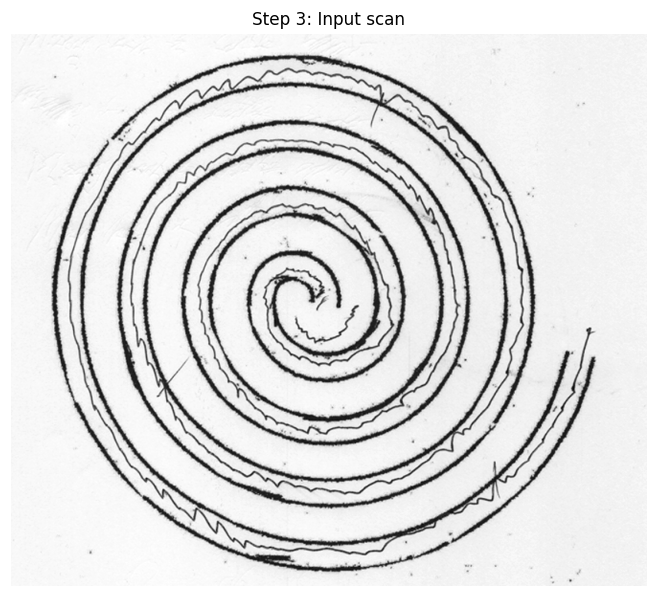

In [4]:
def load(path, target_w=TARGET_W):
    raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if raw is None:
        raise FileNotFoundError(path)
    interp = cv2.INTER_AREA if raw.shape[1] > target_w else cv2.INTER_CUBIC
    return cv2.resize(raw, (target_w, int(raw.shape[0] * target_w / raw.shape[1])), interpolation=interp)

img = load(IMAGE_PATH)
H, W = img.shape
DIAG = np.hypot(H, W)
print(f"Working size: {W} x {H} px")
show(img, "Step 3: Input scan"); plt.show()

## 4. Binarise
**Otsu's method** picks the ink/paper threshold from the intensity histogram. Ink becomes white (255).

[auto] ink threshold (Otsu) = 165  |  ink covers 11.2% of the page


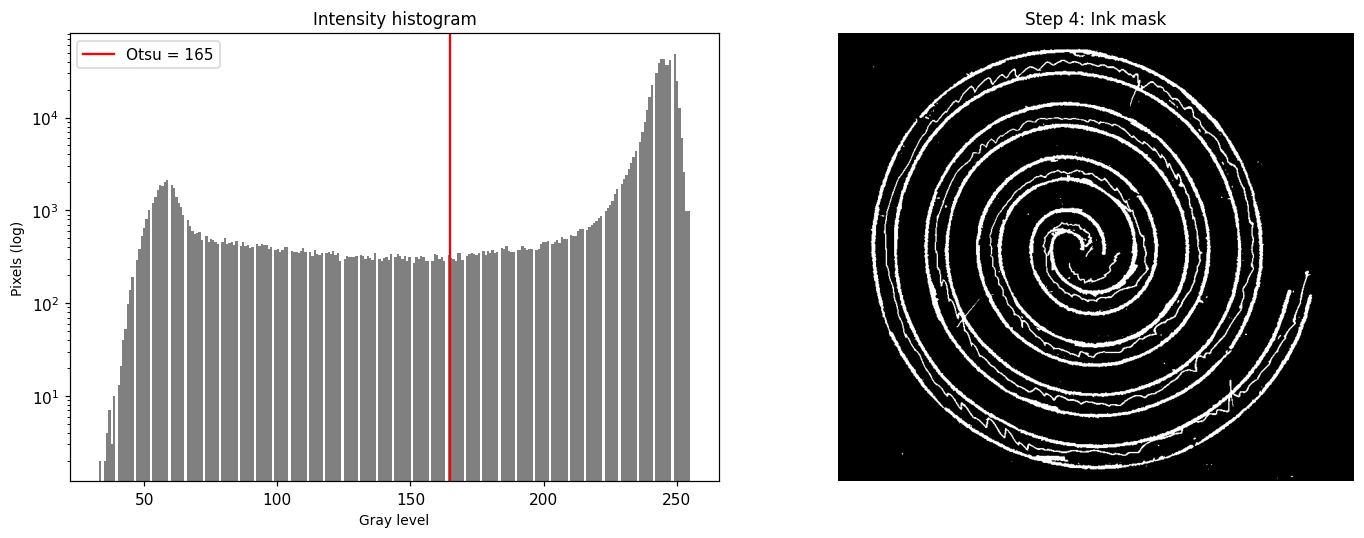

In [5]:
def binarise(gray):
    t, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return t, bw

otsu_t, bw = binarise(img)
print(f"[auto] ink threshold (Otsu) = {otsu_t:.0f}  |  ink covers {(bw > 0).mean()*100:.1f}% of the page")

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].hist(img.ravel(), 256, color="gray"); ax[0].set_yscale("log")
ax[0].axvline(otsu_t, color="red", label=f"Otsu = {otsu_t:.0f}"); ax[0].legend()
ax[0].set_xlabel("Gray level"); ax[0].set_ylabel("Pixels (log)"); ax[0].set_title("Intensity histogram")
show(bw, "Step 4: Ink mask", ax=ax[1]); plt.tight_layout(); plt.show()

## 5. Stroke width: what separates guide from pen
1. Skeletonize the ink into 1 px centre lines.
2. Distance transform: at each skeleton pixel, 2 x (distance to paper) = local stroke width.
3. The width histogram has two modes: thin (pen) and thick (printed guide). Otsu on the widths finds the split.


[auto] width split = 4.38 px  |  pen ~ 2.80 px  |  guide ~ 5.60 px


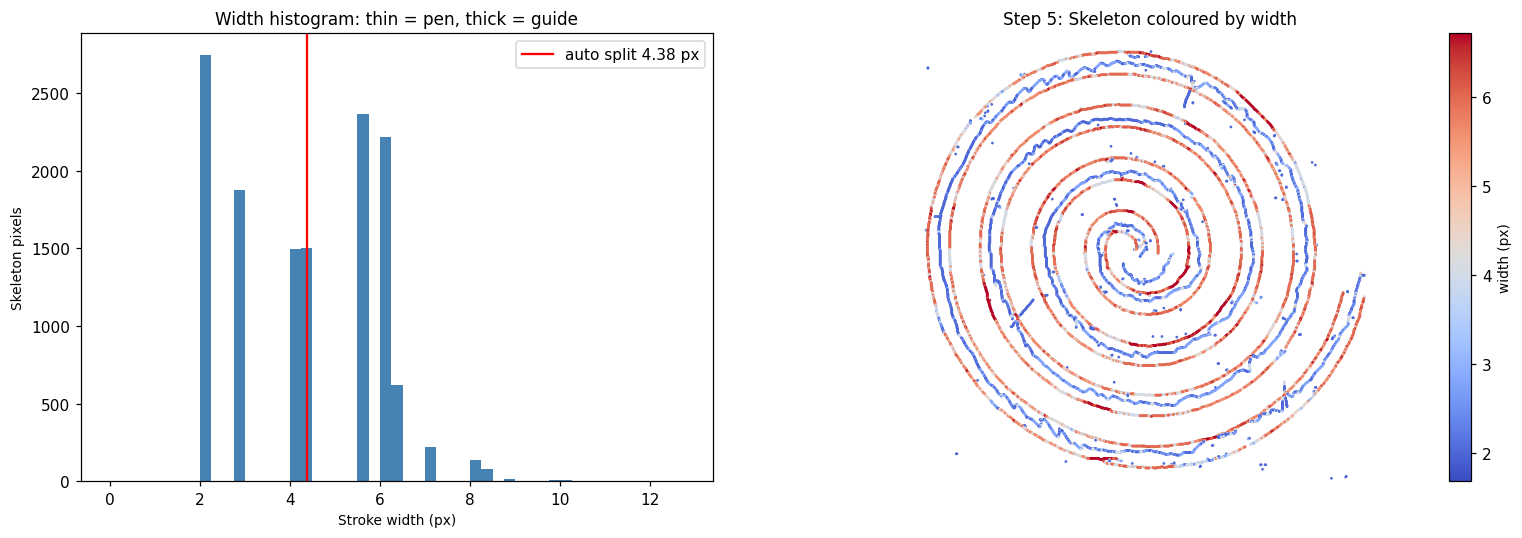

In [6]:
def stroke_widths(bw):
    dist = cv2.distanceTransform(bw, cv2.DIST_L2, 5)
    sk = skeletonize(bw > 0)
    ys, xs = np.nonzero(sk)
    return dist, xs, ys, 2 * dist[ys, xs]

dist, sx, sy, sw = stroke_widths(bw)
width_thr = threshold_otsu(sw)
pen_w   = np.median(sw[sw <= width_thr])
guide_w = np.median(sw[sw >  width_thr])
print(f"[auto] width split = {width_thr:.2f} px  |  pen ~ {pen_w:.2f} px  |  guide ~ {guide_w:.2f} px")
if guide_w / pen_w < 1.4:
    print("WARNING: pen and guide have similar widths; guide separation may be unreliable.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].hist(sw, bins=np.arange(0, sw.max() + 0.5, 0.25), color="steelblue")
ax[0].axvline(width_thr, color="red", label=f"auto split {width_thr:.2f} px")
ax[0].set_xlabel("Stroke width (px)"); ax[0].set_ylabel("Skeleton pixels")
ax[0].set_title("Width histogram: thin = pen, thick = guide"); ax[0].legend()
ax[1].imshow(np.full_like(img, 255), cmap="gray", vmin=0, vmax=255)
s = ax[1].scatter(sx, sy, c=sw, cmap="coolwarm", s=0.6, vmin=pen_w * 0.6, vmax=guide_w * 1.2)
ax[1].set_title("Step 5: Skeleton coloured by width"); ax[1].axis("off")
plt.colorbar(s, ax=ax[1], fraction=0.035, label="width (px)"); plt.tight_layout(); plt.show()

## 6. Build the guide mask
- Rebuild the thick ink: draw a disk (radius = local half-width + 1) at every thick skeleton pixel. This reproduces the guide stroke exactly. (Morphological opening, as in the original code, distorts stroke outlines and leaves halos after subtraction.)
- Keep long thick pieces only: bounding-box diagonal > 5% of the image diagonal. Short thick blobs are usually heavy pen pressure or ink blots, not guide.
- Dilate by 2 px so faint guide edges do not survive as fake pen fragments.

*Pen ink = all ink minus guide.*

[auto] guide = 22 long thick pieces (> 53 px) out of 56 thick pieces


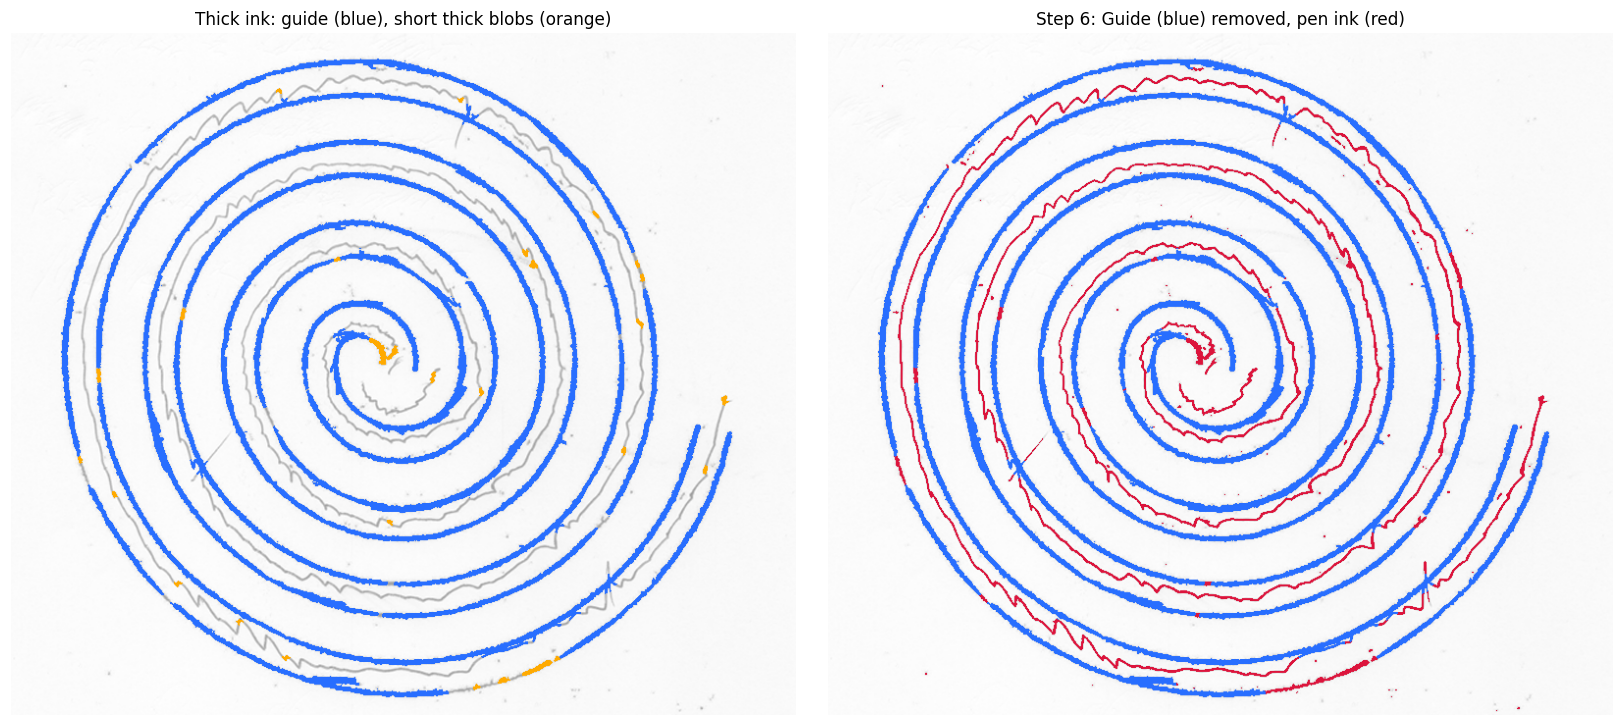

In [7]:
def guide_mask(bw, dist, xs, ys, widths, thr, diag):
    thick = np.zeros_like(bw)
    sel = widths > thr
    for x, y, d in zip(xs[sel], ys[sel], dist[ys[sel], xs[sel]]):
        cv2.circle(thick, (int(x), int(y)), int(np.ceil(d)) + 1, 255, -1)
    thick = cv2.bitwise_and(thick, bw)
    n, lab, st, _ = cv2.connectedComponentsWithStats(thick, connectivity=8)
    d = np.hypot(st[:, 2], st[:, 3]); d[0] = 0
    long_ids = np.where(d > 0.05 * diag)[0]
    g = np.isin(lab, long_ids).astype(np.uint8) * 255
    g = cv2.bitwise_and(cv2.dilate(g, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))), bw)
    return g, thick, len(long_ids), n - 1

guide, thick, n_long, n_thick = guide_mask(bw, dist, sx, sy, sw, width_thr, DIAG)
pen_ink = cv2.bitwise_and(bw, cv2.bitwise_not(guide))
print(f"[auto] guide = {n_long} long thick pieces (> {0.05*DIAG:.0f} px) out of {n_thick} thick pieces")

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
show(faded(img, [(thick, (255, 170, 0)), (guide, BLUE)]), "Thick ink: guide (blue), short thick blobs (orange)", ax=ax[0])
show(faded(img, [(guide, BLUE), (pen_ink, RED)]), "Step 6: Guide (blue) removed, pen ink (red)", ax=ax[1])
plt.tight_layout(); plt.show()

# Conclusion

This notebook takes a scanned spiral drawing test and automatically separates the patient’s pen line from the printed guide. The scan is loaded in grayscale and resized to a fixed width so pixel measurements can be compared between scans. It is not blurred, so the pen line doesn’t smudge into the guide. Otsu’s method then turns the image into ink and paper by finding the natural split between dark and light pixels. 

Next, every ink stroke is thinned to a 1-pixel centre line and its thickness is measured at every point. The printed guide is much thicker than a pen line, so the thickness chart shows two clear groups, and a second automatic threshold splits them into **pen** and **guide**. The guide is rebuilt from its thick parts, only long pieces are kept so that short thick blobs from heavy pen pressure are not mistaken for guide, and it is widened slightly so no faint edges are left behind. 

Finally, the guide is subtracted from the ink, leaving only the patient’s pen line. The plots show the guide in blue and the extracted pen line in red, and that line is ready for cleaning and for measuring drawing accuracy and tremor.